# Dashboard de Vendas

Análise exploratória do dataset de vendas com foco em faturamento, categoria, produtos e tendência temporal.

Objetivos:
- avaliar performance comercial
- identificar categorias e produtos mais relevantes
- tratar valores nulos de forma segura para BI/dashboard
- preparar um resumo executivo para apresentação

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Configuração visual
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_theme(style='whitegrid', context='talk')

# Leitura do arquivo

dados = pd.read_csv(r'C:\Users\joao-\OneDrive\Documents\Projeto_BI_VENDAS\Analise_Exploratoria\vendas.csv')

# Padronização inicial
for col in ['valor_venda', 'quantidade']:
    dados[col] = pd.to_numeric(dados[col], errors='coerce')

dados['data_venda'] = pd.to_datetime(dados['data_venda'], errors='coerce')
dados['categoria'] = dados['categoria'].fillna('Sem categoria')
dados['produto'] = dados['produto'].fillna('Produto não informado')

# Tratamento eficiente de valores nulos
for col in ['valor_venda', 'quantidade']:
    dados[col] = dados[col].fillna(dados.groupby('categoria')[col].transform('median'))
    dados[col] = dados[col].fillna(dados.groupby('produto')[col].transform('median'))
    dados[col] = dados[col].fillna(dados[col].median())

# Ajustes finais

dados['quantidade'] = dados['quantidade'].round().astype(int)
dados['valor_venda'] = dados['valor_venda'].astype(float)
dados['receita'] = (dados['valor_venda'] * dados['quantidade']).round(2)

# Exportação do dataframe tratado para análise no Power BI
caminho_exportacao = r'C:\Users\joao-\OneDrive\Documents\Projeto_BI_VENDAS\Analise_Exploratoria\vendas_tratadas.csv'
dados.to_csv(caminho_exportacao, sep=',', decimal=',', float_format='%.2f', index=False, encoding='utf-8-sig')
print(f'Dataframe tratado exportado para: {caminho_exportacao}')
print(f"Total de receita validado: R$ {dados['receita'].sum():,.2f}")

dados.head()

Dataframe tratado exportado para: C:\Users\joao-\OneDrive\Documents\Projeto_BI_VENDAS\Analise_Exploratoria\vendas_tratadas.csv
Total de receita validado: R$ 810,828.88


,id_venda,data_venda,id_cliente,id_produto,produto,categoria,valor_venda,quantidade,receita
0,1,2023-02-07,109,8,Livro: A Guerra dos Tronos,Livros,2677.12,2,5354.24
1,2,2023-01-11,139,7,Headset Surround 7.1,Áudio,1210.10,1,1210.10
2,3,2023-02-16,104,17,Mousepad Gamer XXL,Periféricos,2393.06,2,4786.12
3,4,2023-03-20,145,17,Mousepad Gamer XXL,Periféricos,3925.92,3,11777.76
4,5,2023-02-16,134,16,Memória RAM 16GB DDR5,Componentes,4702.89,1,4702.89


# Estrutura e qualidade dos dados

In [3]:
print(f'Formato do dataframe: {dados.shape}')
print('\nTipos das colunas:')
print(dados.dtypes)
print('\nValores ausentes antes do tratamento:')
print(pd.read_csv(r'C:\Users\joao-\OneDrive\Documents\Projeto_BI_VENDAS\Analise_Exploratoria\vendas.csv').isnull().sum())
print('\nValores ausentes após o tratamento:')
print(dados.isnull().sum())
print('\nResumo estatístico:')
print(dados.describe(include='all').T)

Formato do dataframe: (120, 9)

Tipos das colunas:
id_venda                int64
data_venda     datetime64[us]
id_cliente              int64
id_produto              int64
produto                   str
categoria                 str
valor_venda           float64
quantidade              int64
receita               float64
dtype: object

Valores ausentes antes do tratamento:
id_venda       0
data_venda     0
id_cliente     0
id_produto     0
produto        0
categoria      0
valor_venda    0
quantidade     0
dtype: int64

Valores ausentes após o tratamento:
id_venda       0
data_venda     0
id_cliente     0
id_produto     0
produto        0
categoria      0
valor_venda    0
quantidade     0
receita        0
dtype: int64

Resumo estatístico:
             count unique                  top freq                 mean  \
id_venda     120.0    NaN                  NaN  NaN                 60.5   
data_venda     120    NaN                  NaN  NaN  2023-02-16 07:48:00   
id_cliente   120.0    NaN

In [4]:
# KPIs principais

faturamento_total = dados['receita'].sum()
ticket_medio = dados['receita'].mean()
valor_medio_venda = dados['valor_venda'].mean()
quantidade_media = dados['quantidade'].mean()
qtd_total_itens = dados['quantidade'].sum()

print(f'Faturamento total: R$ {faturamento_total:,.2f}')
print(f'Ticket médio por venda: R$ {ticket_medio:,.2f}')
print(f'Valor médio da venda: R$ {valor_medio_venda:,.2f}')
print(f'Quantidade média por venda: {quantidade_media:.2f}')
print(f'Quantidade total de itens vendidos: {qtd_total_itens:,}')
print(f'\nCorrelação entre quantidade e receita: {dados["quantidade"].corr(dados["receita"]):.3f}')

Faturamento total: R$ 810,828.88
Ticket médio por venda: R$ 6,756.91
Valor médio da venda: R$ 2,742.48
Quantidade média por venda: 2.42
Quantidade total de itens vendidos: 291

Correlação entre quantidade e receita: 0.668


In [5]:
# Agregações por categoria e produto

categoria_agg = (
    dados.groupby('categoria', as_index=False)
    .agg(
        receita_total=('receita', 'sum'),
        qtd_vendas=('id_venda', 'count'),
        ticket_medio=('receita', 'mean'),
        valor_medio_unitario=('valor_venda', 'mean'),
        quantidade_total=('quantidade', 'sum')
    )
    .sort_values('receita_total', ascending=False)
)

produto_agg = (
    dados.groupby('produto', as_index=False)
    .agg(receita_total=('receita', 'sum'), quantidade_total=('quantidade', 'sum'))
    .sort_values('receita_total', ascending=False)
    .head(10)
)

print('Top categorias por faturamento:')
display(categoria_agg)
print('\nTop 10 produtos por faturamento:')
display(produto_agg)

Top categorias por faturamento:


,categoria,receita_total,qtd_vendas,ticket_medio,valor_medio_unitario,quantidade_total
6,Periféricos,307921.82,43,7160.972558,2872.891860,108
4,Livros,140285.75,20,7014.287500,2689.328000,49
3,Eletrônicos,124973.54,15,8331.569333,2885.424667,42
2,Decoração,109156.43,13,8396.648462,3095.460000,36
0,Colecionáveis,55658.46,8,6957.307500,3294.731250,17
1,Componentes,35468.07,11,3224.370000,1848.944545,22
7,Áudio,29281.47,6,4880.245000,2727.015000,11
5,Móveis,8083.34,4,2020.835000,1298.995000,6



Top 10 produtos por faturamento:


,produto,receita_total,quantidade_total
9,Mesa Digitalizadora,121141.96,38
13,Notebook Gamer,78082.44,26
7,Luminária de Mesa LED,61397.75,14
11,Mouse Gamer Sem Fio,58387.27,21
4,Livro: A Guerra dos Tronos,56314.76,19
10,"Monitor Ultrawide 34""",56129.82,18
0,Action Figure: Batman,55658.46,17
2,Caneca Star Wars,47758.68,22
16,Smartphone Pro,46891.10,16
5,Livro: Duna,45881.42,14


In [6]:
# Filtro por categoria e série temporal

# Lista estática de categorias para evitar recalcular valores a cada interação
categorias = ['Todas'] + sorted(dados['categoria'].dropna().unique().tolist())

# Série temporal mensal calculada uma vez
mensal_agg = (
    dados.assign(mes=dados['data_venda'].dt.to_period('M').dt.to_timestamp())
    .groupby('mes', as_index=False)['receita']
    .sum()
    .rename(columns={'receita': 'receita_total'})
)
mensal_agg['mes'] = mensal_agg['mes'].dt.strftime('%Y-%m')

# Função eficiente para filtrar dados por categoria

def filtrar_categoria(categoria='Todas'):
    if categoria == 'Todas':
        return dados
    return dados.loc[dados['categoria'].eq(categoria)].copy()

# Exemplo de uso em dashboard: filtra sem repetir o agrupamento completo da série mensal
categoria_atual = 'Todas'
df_filtrado = filtrar_categoria(categoria_atual)

print(f'Categoria selecionada: {categoria_atual}')
print(f'Qtd. de registros filtrados: {len(df_filtrado)}')
print('\nReceita por mês:')
display(mensal_agg)

Categoria selecionada: Todas
Qtd. de registros filtrados: 120

Receita por mês:


,mes,receita_total
0,2023-01,234634.61
1,2023-02,282351.34
2,2023-03,293842.93


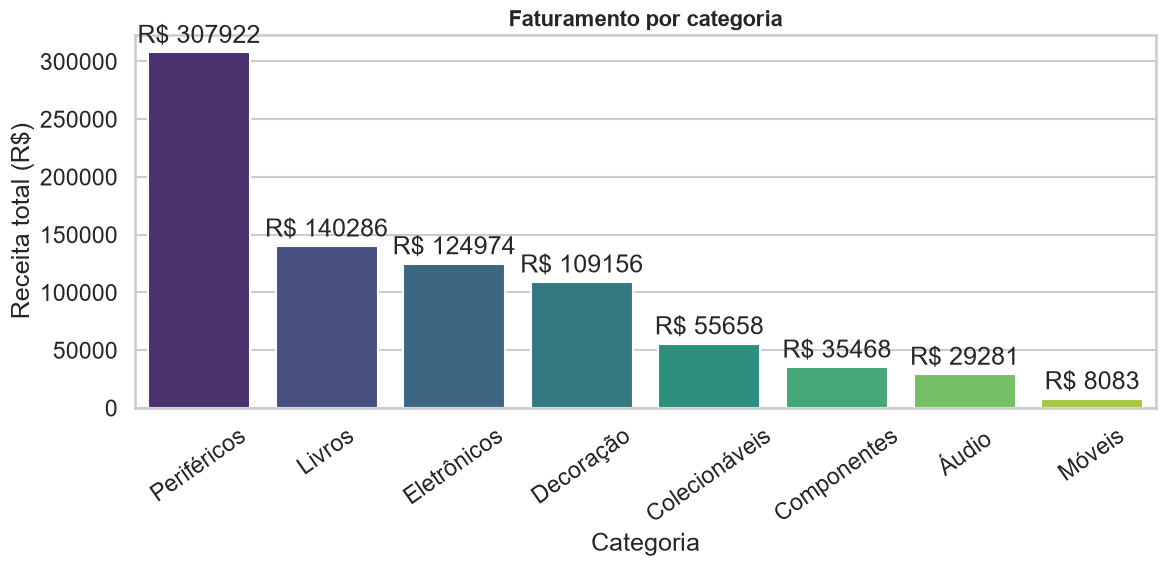

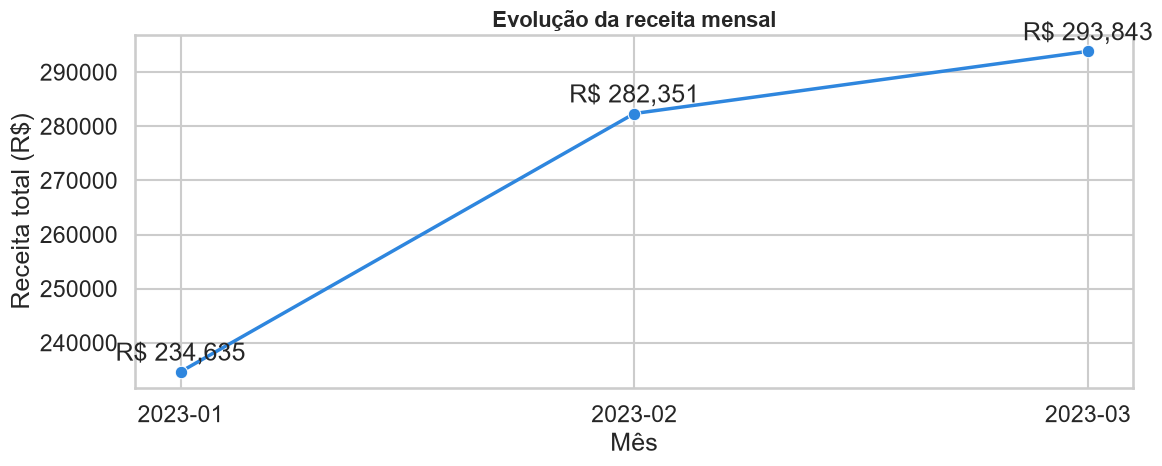

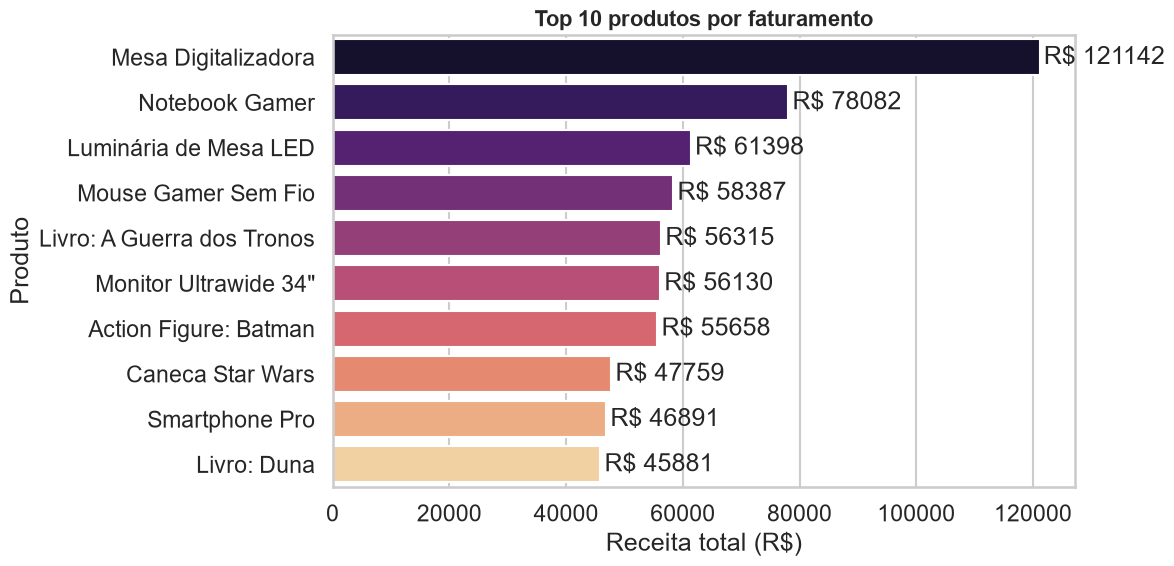

In [7]:
# Gráficos principais

# 1) Faturamento por categoria
plt.figure(figsize=(12, 6))
ax = sns.barplot(
    data=categoria_agg,
    x='categoria',
    hue='categoria',
    y='receita_total',
    palette='viridis',
    legend=False,
    order=categoria_agg['categoria']
)
for container in ax.containers:
    ax.bar_label(container, fmt='R$ %.0f', padding=3)
plt.title('Faturamento por categoria', fontsize=16, weight='bold')
plt.xlabel('Categoria')
plt.ylabel('Receita total (R$)')
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

# 2) Receita mensal
plt.figure(figsize=(12, 5))
ax = sns.lineplot(data=mensal_agg, x='mes', y='receita_total', marker='o', linewidth=2.5, color='#2E86DE')
for x, y in zip(ax.get_xticks(), mensal_agg['receita_total']):
    ax.annotate(f'R$ {y:,.0f}', (x, y), textcoords='offset points', xytext=(0, 8), ha='center')
plt.title('Evolução da receita mensal', fontsize=16, weight='bold')
plt.xlabel('Mês')
plt.ylabel('Receita total (R$)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 3) Top 10 produtos por receita
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=produto_agg, x='receita_total', y='produto', hue='produto', palette='magma', dodge=False, legend=False, orient='h', order=produto_agg['produto'])
for container in ax.containers:
    ax.bar_label(container, fmt='R$ %.0f', padding=3)
plt.title('Top 10 produtos por faturamento', fontsize=16, weight='bold')
plt.xlabel('Receita total (R$)')
plt.ylabel('Produto')
plt.tight_layout()
plt.show()

In [8]:
# Resumo executivo para apresentação

resumo = f"""
## Resumo executivo

- Faturamento total: R$ {dados['receita'].sum():,.2f}
- Ticket médio por venda: R$ {dados['receita'].mean():,.2f}
- Quantidade média por venda: {dados['quantidade'].mean():.2f}
- Categoria com maior faturamento: {categoria_agg.iloc[0]['categoria']} com R$ {categoria_agg.iloc[0]['receita_total']:,.2f}
- Produto com maior faturamento: {produto_agg.iloc[0]['produto']} com R$ {produto_agg.iloc[0]['receita_total']:,.2f}
- Tendência: a receita mensal cresceu ao longo do período analisado, indicando aumento de demanda ou melhor performance comercial.

### Observações
- O tratamento de nulos foi realizado de forma eficiente utilizando a mediana por categoria e produto, preservando o comportamento real do dataset.
- A categoria de {categoria_agg.iloc[0]['categoria']} concentra a maior parte do faturamento e deve continuar sendo foco de estratégia.
- A correlação entre quantidade e receita está em {dados['quantidade'].corr(dados['receita']):.2f}, indicando relação positiva moderada entre volume vendido e valores gerados.
"""

display(Markdown(resumo))


## Resumo executivo

- Faturamento total: R$ 810,828.88
- Ticket médio por venda: R$ 6,756.91
- Quantidade média por venda: 2.42
- Categoria com maior faturamento: Periféricos com R$ 307,921.82
- Produto com maior faturamento: Mesa Digitalizadora com R$ 121,141.96
- Tendência: a receita mensal cresceu ao longo do período analisado, indicando aumento de demanda ou melhor performance comercial.

### Observações
- O tratamento de nulos foi realizado de forma eficiente utilizando a mediana por categoria e produto, preservando o comportamento real do dataset.
- A categoria de Periféricos concentra a maior parte do faturamento e deve continuar sendo foco de estratégia.
- A correlação entre quantidade e receita está em 0.67, indicando relação positiva moderada entre volume vendido e valores gerados.
